# **Exercício 3 \- cap 8 e 9**

 **Discente:** Raphael Ramos da Silva

Para o laboratório disponibilizado no [**link**](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.CNN/Chapter.CNNCrack/lab.html):

- Executar o laboratório de classificação de trincas em fotos de afloramentos geológicos usando AlexNet no MATLAB (ou Python).
- Enviar notebook (ou script) com resultados E interpretação destes.

**1. Pick the training set manually by yourself. You can focus on big crack only or small crack only. See how the result will be looks like.**

O script `test_example_CNN_1.m` contém a implementação desta questão.

Foram selecionados 200 pontos onde não tinham fraturas, e outros 200 onde tinham fraturas pequenas.

Na arquitetura original, a rede possui as seguintes camadas

- Convolução 1: 6 mapas, kernel 5x5 (saída: 28x28)
- Sub-amostragem 1: escala 2 (saída: 14x14)
- Convolução 2: 12 mapas, kernel 5x5 (saída 10x10)
- Sub-amostragem 2: escala 2 (saída: 5x5)
- Entradas na camada totalmnnte conectadas: 5 * 5 * 12 = 300

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg


def visualizar(figuras, largura=7, altura=6):
    """Exibe as imagens lado a lado, uma por coluna, com o título acima de cada uma."""
    fig, axes = plt.subplots(1, len(figuras), figsize=(largura * len(figuras), altura), squeeze=False)
    for ax, (titulo, caminho) in zip(axes[0], figuras):
        ax.imshow(mpimg.imread(caminho))
        ax.set_title(titulo, fontweight="bold")
        ax.axis("off")
    fig.tight_layout()
    plt.show()

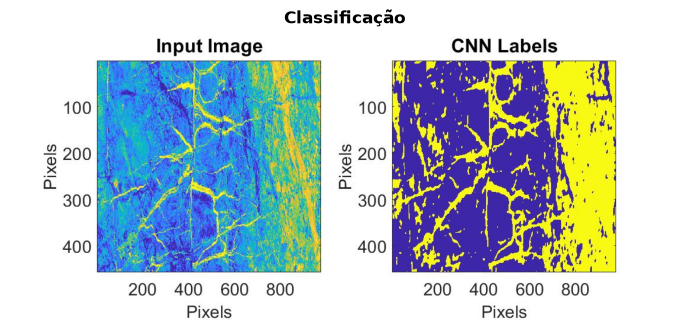

In [2]:
visualizar([
    ("Classificação", "imagens/test_example_CNN_1-small_cracks_train.jpg"),
])

**Modify the structure of CNN. See how the CNN parameter will change the result.**

O script `test_example_CNN_2.m` contém a implementação desta questão. Ele é uma cópia de `test_example_CNN_1.m` (mesmo conjunto de treino, tamanho dos patches e parâmetros de treinamento: `alpha = 1`, `batchsize = 20`, `numepochs = 10`), alterando apenas a estrutura da rede.

Os patches de entrada têm 17x17 pixels e são interpolados para 32x32. A tabela abaixo compara as duas configurações:

- Convolução 1: 8 mapas, kernel 3x3 (saída: 30x30)
- Sub-amostragem 1: escala 2 (saída: 14x14)
- Convolução 2: 16 mapas, kernel 4x4 (saída 12x12)
- Sub-amostragem 2: escala 2 (saída: 6x6)
- Entradas na camada totalmnnte conectadas: 6 * 6 * 16 = 576

Resumindo, as mudanças foram:

- *Kernels menores*: cada filtro olha uma região menor do patch, o que favorece a detecção de detalhes finos, como as bordas das trincas pequenas.
- *Mais mapas de características*: rede consegue aprender mais tipos de padrões em cada camada.

Com `opts.numepochs = 10`, essa nova configuracao prevê a mesma classe para todos os pixels. Então, o resultado da inferência é um painel todo em ciano. Ou seja, o treinamento "colapsa" para apenas uma classe.

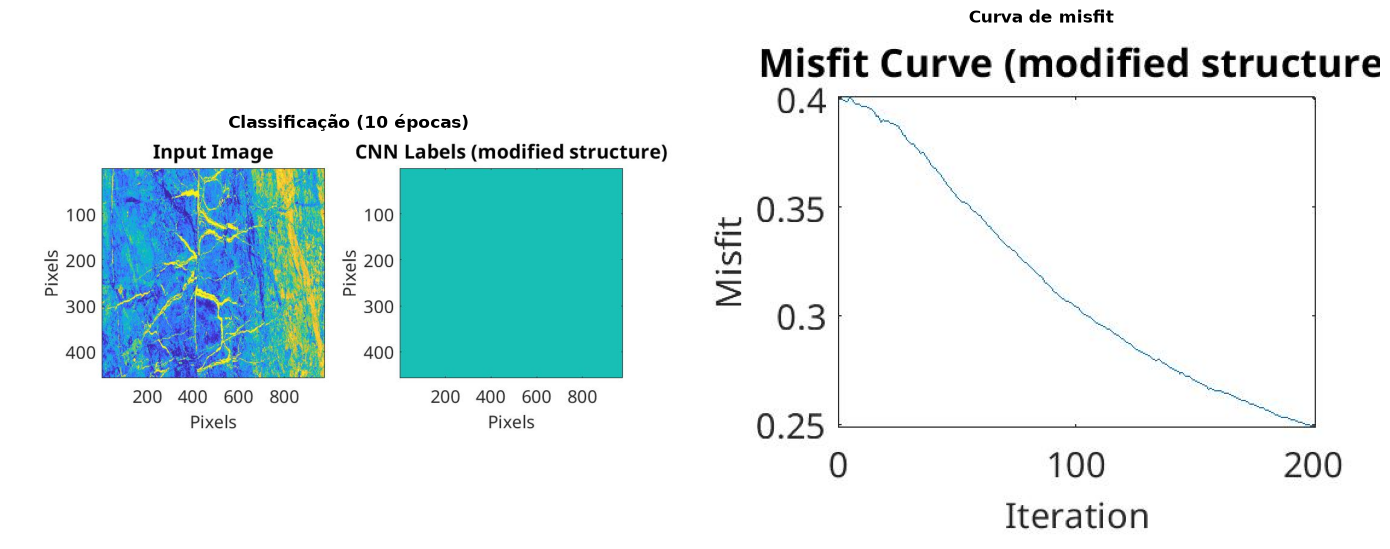

In [3]:
visualizar([
    ("Classificação (10 épocas)", "imagens/test_example_CNN_2-small_cracks_train_10epochs.jpg"),
    ("Curva de misfit", "imagens/test_example_CNN_2-small_cracks_train_10epochs_misfit.jpg"),
])

**Increase the iteration number to 100. How the result will change? Why? Is there anyway to prevent this problem.**

Utilizando o mesmo script `test_example_CNN_2.m`, mas com `opts.numepochs = 100`, o "colapso" da rede é superado e ela volta a separar as regiões com e sem trincas.

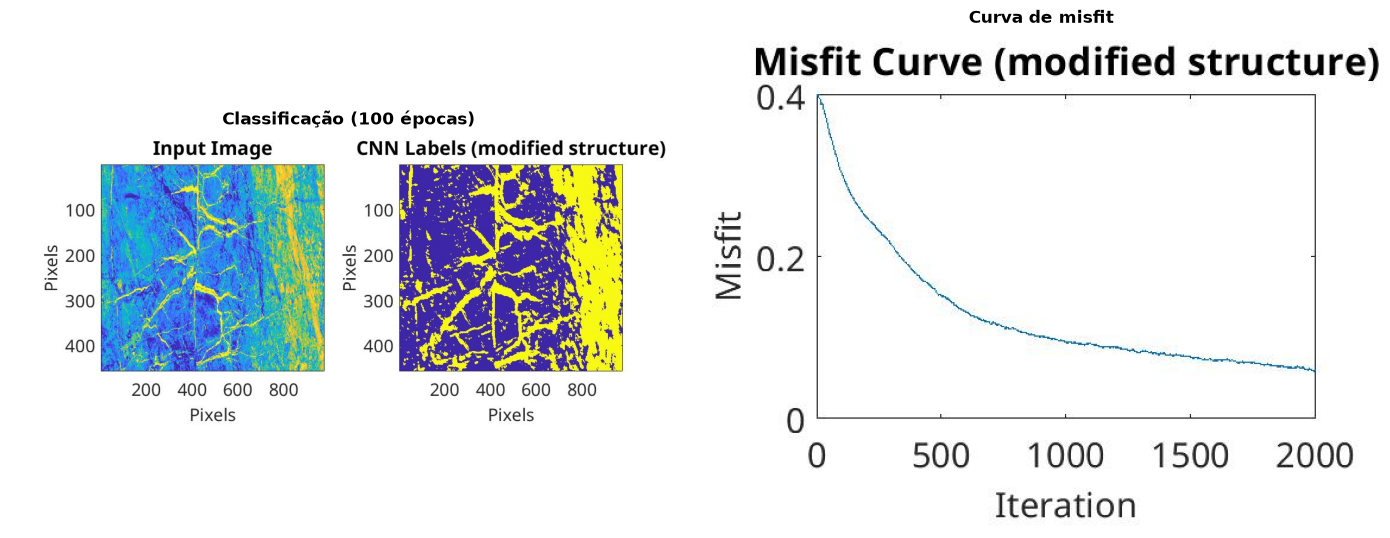

In [4]:
visualizar([
    ("Classificação (100 épocas)", "imagens/test_example_CNN_2-small_cracks_train_100epochs.jpg"),
    ("Curva de misfit", "imagens/test_example_CNN_2-small_cracks_train_100epochs_misfit.jpg"),
])

Isso acontece porque a camada totalmente conectada tem quase o dobro de entradas (576 contra 300) e mais pesos para ajustar. Pelas curvas de erro (*misfit*), habilitadas pelo comando `plot(cnn.rL)`, pode-se concluir que

- `numepochs = 10` não é suficiente para o erro sair de `0.25`, e a rede responde sempre a mesma classe. 
- `numepochs = 100` faz com que a rede "vença" o plateau, porque o erro cai e, consequentemente, os filtros passam a distinguir trincas do fundo.

Ou seja, o resultado indesejável com 10 épocas não era limitação da arquitetura, e sim falta de treinamento.

No entanto, permitir o treino por mais épocas e com poucos dados, causa o overfitting (a rede pode começar a "decorar" o conjunto de treino): o erro de treino continua caindo, mas a classificação da imagem completa fica mais ruidosa. Assim, entre as formas de mitigar esse problema, estão: aumentar o conjunto de trieno, usa regularização (ignorar a ativação de alguns pesos com a técnica de  *dropout* ou reduzir o número de parâmetros da rede), normalizar a entrada ou camadas de normalização em *batch* na rede neural e usar funções de ativação que não deixam a rede estagnar com gradientes pequenos, como a ReLU.

**Try to do multi\-class classification using this code. Such as background, crack class 1 and crack class 2.**

O script `test_example_CNN_3.m` contém a implementação desta questão. Ele é uma cópia de `test_example_CNN.m` (mesma estrutura de rede e parâmetros de treinamento), considerando três classes: `background`, `small_crack` e `big_crack`.

As mudanças foram:

- Conjunto de treino: 600 pontos, sendo 200 de `background`, 200 de `small_crack` e 200 de `big_crack`. Os pontos são selecionados manualmente com `ginput` (uma figura por classe) e salvos em `data/multiclass_train.mat`. Nas execuções seguintes, o arquivo é carregado diretamente.

- Rótulos: cada ponto recebe um vetor *one-hot* de 3 posições (`[1;0;0]` para `background`, `[0;1;0]` para `small_crack` e `[0;0;1]` para `big_crack`), formando uma matriz 3x600. Como o `cnnsetup` define o número de neurônios de saída por `size(y,1)`, a camada de saída passa a ter 3 neurônios sem nenhuma alteração no código da rede.

- Patches de treino: passam a ser `3*ntrain = 600`. Com `batchsize = 20`, são 30 minibatches por época.

- Classificação: cada pixel recebe a classe do neurônio de saída com maior ativação, mapeada para `0` (`background`), `1` (`small_crack`) e `2` (`big_crack`)

O resultado é mostrado na figura abaixo:

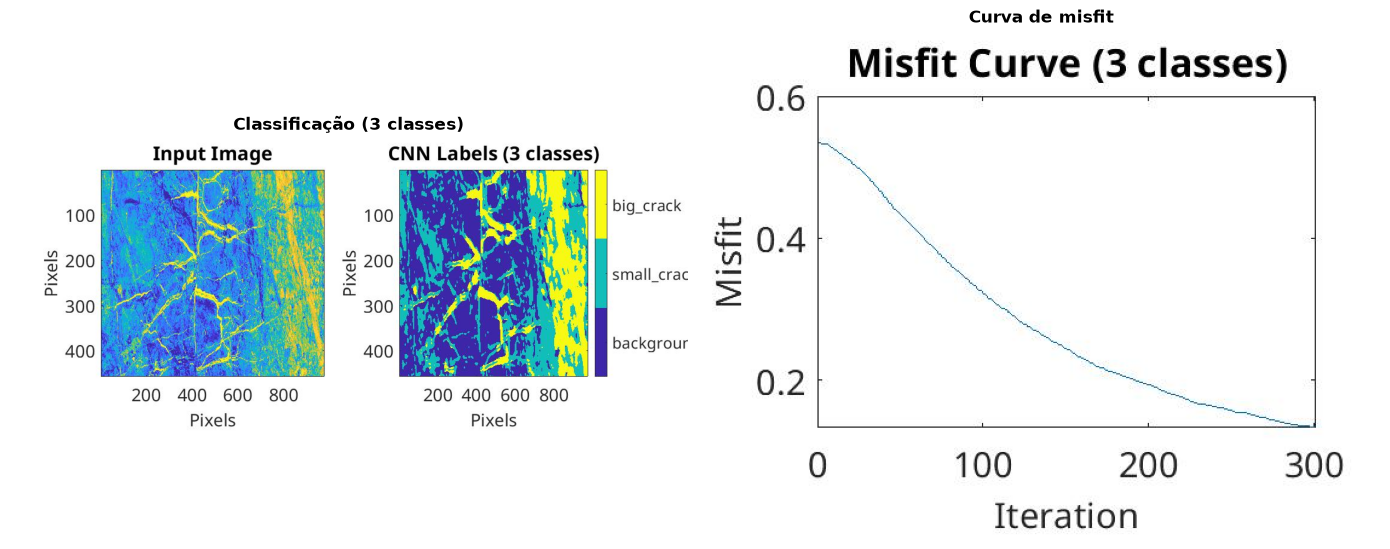

In [5]:
visualizar([
    ("Classificação (3 classes)", "imagens/test_example_CNN_3-multiclass.jpg"),
    ("Curva de misfit", "imagens/test_example_CNN_3-multiclass_misfit.jpg"),
])

As trincas grandes, as fraturas claras e largas na região central da imagem (entre os pixels 200 e 650 em x), foram bem identificadas como `big_crack`, visto que a rede reproduz a geometria da rede de fraturas principal, inclusive suas ramificações.

A classe `small_crack` aparece em faixas finas e alongadas espalhadas pelo fundo, o que é coerente com as fraturas pequenas da imagem. No entanto, ela também aparece em manchas sem uma forma de trinca bem definida, principalmente no lado esquerdo. Isso indica confusão entre `small_crack` e variações de textura do `background`.

A região à direita (x > 700), onde a rocha é mais clara, foi classificada quase toda como `big_crack` e `small_crack`, embora não seja uma trinca. Isso implica que a rede associa as trincas grandes principalmente à intensidade alta dos pixels, e não à forma da fratura.